In [2]:
import torch
import torchvision

print("PyTorch version:", torch.__version__)
print("Torchvision version:", torchvision.__version__)
print("GPU available:", torch.cuda.is_available())

PyTorch version: 2.11.0+cpu
Torchvision version: 0.26.0+cpu
GPU available: False


In [1]:
import torch

print("GPU available:", torch.cuda.is_available())

GPU available: True


In [2]:
import zipfile
import os

zip_path = "/content/Orange Dataset.zip"
extract_path = "/content/avocado_dataset"

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset extracted successfully!")
print("Files and folders:")
print(os.listdir(extract_path))

Dataset extracted successfully!
Files and folders:
['test', 'train']


In [3]:
import os

DATA_DIR = "/content/avocado_dataset"

for split in ["train", "test"]:
    print(f"\n{split.upper()} DATASET")

    for class_name in sorted(os.listdir(os.path.join(DATA_DIR, split))):
        class_path = os.path.join(DATA_DIR, split, class_name)

        if os.path.isdir(class_path):
            image_count = len([
                f for f in os.listdir(class_path)
                if f.lower().endswith((".jpg", ".jpeg", ".png"))
            ])
            print(f"{class_name}: {image_count} images")


TRAIN DATASET
blackspot: 184 images
canker: 179 images
fresh: 281 images
grenning: 347 images

TEST DATASET
blackspot: 22 images
canker: 22 images
fresh: 33 images
grenning: 22 images


In [4]:
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

DATA_DIR = "/content/avocado_dataset"

train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

train_dataset = datasets.ImageFolder(
    f"{DATA_DIR}/train",
    transform=train_transform
)

test_dataset = datasets.ImageFolder(
    f"{DATA_DIR}/test",
    transform=test_transform
)

train_loader = DataLoader(
    train_dataset, batch_size=32, shuffle=True
)

test_loader = DataLoader(
    test_dataset, batch_size=32, shuffle=False
)

print("Classes:", train_dataset.classes)
print("Training images:", len(train_dataset))
print("Testing images:", len(test_dataset))
print("Preprocessing complete!")

Classes: ['blackspot', 'canker', 'fresh', 'grenning']
Training images: 991
Testing images: 99
Preprocessing complete!


In [5]:
import torch
import torch.nn as nn
from torchvision import models

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Load pretrained MobileNetV2
weights = models.MobileNet_V2_Weights.DEFAULT
model = models.mobilenet_v2(weights=weights)

# Freeze pretrained layers
for param in model.features.parameters():
    param.requires_grad = False

# Replace final layer for our 4 classes
input_features = model.classifier[1].in_features
model.classifier[1] = nn.Linear(input_features, len(train_dataset.classes))

model = model.to(device)

print("MobileNetV2 model created!")
print("Device:", device)
print("Number of classes:", len(train_dataset.classes))

Downloading: "https://download.pytorch.org/models/mobilenet_v2-7ebf99e0.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v2-7ebf99e0.pth


100%|██████████| 13.6M/13.6M [00:00<00:00, 165MB/s]


MobileNetV2 model created!
Device: cuda
Number of classes: 4


In [6]:
import torch.nn as nn
import torch.optim as optim

criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    model.classifier.parameters(),
    lr=0.001
)

epochs = 5

for epoch in range(epochs):
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item()
        _, predicted = torch.max(outputs, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    accuracy = 100 * correct / total

    print(
        f"Epoch [{epoch+1}/{epochs}] "
        f"Loss: {running_loss/len(train_loader):.4f} "
        f"Training Accuracy: {accuracy:.2f}%"
    )

print("MobileNetV2 training completed!")

Epoch [1/5] Loss: 0.7787 Training Accuracy: 80.22%
Epoch [2/5] Loss: 0.3088 Training Accuracy: 96.67%
Epoch [3/5] Loss: 0.1923 Training Accuracy: 97.58%
Epoch [4/5] Loss: 0.1546 Training Accuracy: 97.88%
Epoch [5/5] Loss: 0.1497 Training Accuracy: 96.57%
MobileNetV2 training completed!


In [7]:
from sklearn.metrics import accuracy_score

model.eval()

all_preds = []
all_labels = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)

        outputs = model(images)
        predictions = outputs.argmax(dim=1)

        all_preds.extend(predictions.cpu().numpy())
        all_labels.extend(labels.numpy())

test_accuracy = accuracy_score(all_labels, all_preds)

print("MobileNetV2 Test Accuracy:",
      round(test_accuracy * 100, 2), "%")

MobileNetV2 Test Accuracy: 94.95 %


In [8]:
from sklearn.metrics import classification_report

print("MobileNetV2 Classification Report:\n")

print(classification_report(
    all_labels,
    all_preds,
    target_names=train_dataset.classes
))

MobileNetV2 Classification Report:

              precision    recall  f1-score   support

   blackspot       0.91      0.91      0.91        22
      canker       0.90      0.86      0.88        22
       fresh       0.97      1.00      0.99        33
    grenning       1.00      1.00      1.00        22

    accuracy                           0.95        99
   macro avg       0.95      0.94      0.94        99
weighted avg       0.95      0.95      0.95        99



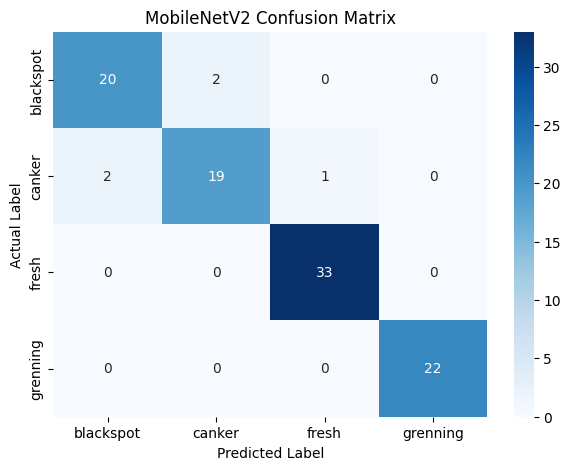

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(all_labels, all_preds)

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=train_dataset.classes,
    yticklabels=train_dataset.classes
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("MobileNetV2 Confusion Matrix")
plt.show()

In [10]:
import pandas as pd

comparison = pd.DataFrame({
    "Model": ["SVM", "Random Forest", "MobileNetV2"],
    "Test Accuracy (%)": [95.96, 96.97, 94.95],
    "Macro Precision": [0.96, 0.97, 0.95],
    "Macro Recall": [0.95, 0.97, 0.94],
    "Macro F1-score": [0.95, 0.97, 0.94]
})

print(comparison.to_string(index=False))

        Model  Test Accuracy (%)  Macro Precision  Macro Recall  Macro F1-score
          SVM              95.96             0.96          0.95            0.95
Random Forest              96.97             0.97          0.97            0.97
  MobileNetV2              94.95             0.95          0.94            0.94


In [11]:
import torch

torch.save(
    model.state_dict(),
    "/content/mobilenetv2_orange.pth"
)

print("Model saved successfully!")

Model saved successfully!


In [12]:
from google.colab import files

uploaded = files.upload()

Saving orange.webp to orange.webp


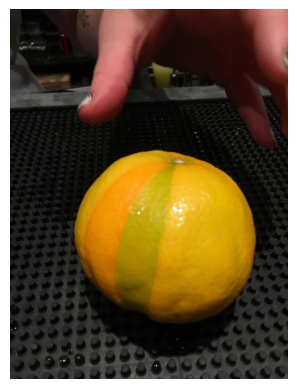

Predicted class: fresh
Model confidence: 54.56%


In [13]:
from PIL import Image
import torch
from torchvision import transforms
import matplotlib.pyplot as plt

# Load uploaded image
image = Image.open("orange.webp").convert("RGB")

# Same preprocessing used during testing
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        [0.485, 0.456, 0.406],
        [0.229, 0.224, 0.225]
    )
])

image_tensor = transform(image).unsqueeze(0)

# Predict
model.eval()

device = next(model.parameters()).device
image_tensor = image_tensor.to(device)

with torch.no_grad():
    outputs = model(image_tensor)
    probabilities = torch.softmax(outputs, dim=1)
    predicted_index = probabilities.argmax(dim=1).item()

class_names = train_dataset.classes
predicted_class = class_names[predicted_index]
confidence = probabilities[0][predicted_index].item() * 100

plt.imshow(image)
plt.axis("off")
plt.show()

print("Predicted class:", predicted_class)
print(f"Model confidence: {confidence:.2f}%")

In [14]:
from google.colab import files

uploaded = files.upload()

Saving orange_2.jpg to orange_2.jpg


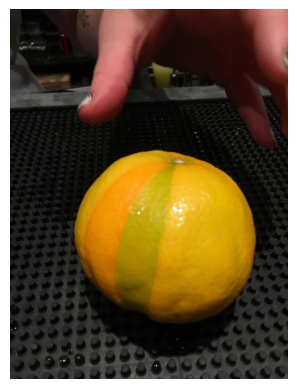

Predicted class: fresh
Model confidence: 54.56%


In [15]:
from PIL import Image
import torch
from torchvision import transforms
import matplotlib.pyplot as plt

# Load uploaded image
image = Image.open("orange.webp").convert("RGB")

# Same preprocessing used during testing
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        [0.485, 0.456, 0.406],
        [0.229, 0.224, 0.225]
    )
])

image_tensor = transform(image).unsqueeze(0)

# Predict
model.eval()

device = next(model.parameters()).device
image_tensor = image_tensor.to(device)

with torch.no_grad():
    outputs = model(image_tensor)
    probabilities = torch.softmax(outputs, dim=1)
    predicted_index = probabilities.argmax(dim=1).item()

class_names = train_dataset.classes
predicted_class = class_names[predicted_index]
confidence = probabilities[0][predicted_index].item() * 100

plt.imshow(image)
plt.axis("off")
plt.show()

print("Predicted class:", predicted_class)
print(f"Model confidence: {confidence:.2f}%")

In [17]:
from google.colab import files

uploaded = files.upload()

Saving orange_2.jpg to orange_2 (2).jpg


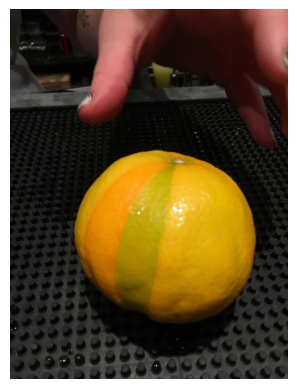

Predicted class: fresh
Model confidence: 54.56%


In [18]:
from PIL import Image
import torch
from torchvision import transforms
import matplotlib.pyplot as plt

# Load uploaded image
image = Image.open("orange.webp").convert("RGB")

# Same preprocessing used during testing
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        [0.485, 0.456, 0.406],
        [0.229, 0.224, 0.225]
    )
])

image_tensor = transform(image).unsqueeze(0)

# Predict
model.eval()

device = next(model.parameters()).device
image_tensor = image_tensor.to(device)

with torch.no_grad():
    outputs = model(image_tensor)
    probabilities = torch.softmax(outputs, dim=1)
    predicted_index = probabilities.argmax(dim=1).item()

class_names = train_dataset.classes
predicted_class = class_names[predicted_index]
confidence = probabilities[0][predicted_index].item() * 100

plt.imshow(image)
plt.axis("off")
plt.show()

print("Predicted class:", predicted_class)
print(f"Model confidence: {confidence:.2f}%")

In [20]:
from google.colab import files

uploaded = files.upload()

Saving orange_2.jpg to orange_2 (3).jpg


In [24]:
image = Image.open("orange_2.jpg").convert("RGB")

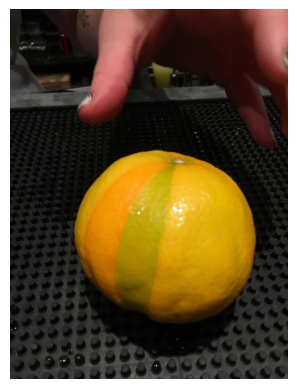

Predicted class: fresh
Model confidence: 54.56%


In [25]:
from PIL import Image
import torch
from torchvision import transforms
import matplotlib.pyplot as plt

# Load uploaded image
image = Image.open("orange.webp").convert("RGB")

# Same preprocessing used during testing
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        [0.485, 0.456, 0.406],
        [0.229, 0.224, 0.225]
    )
])

image_tensor = transform(image).unsqueeze(0)

# Predict
model.eval()

device = next(model.parameters()).device
image_tensor = image_tensor.to(device)

with torch.no_grad():
    outputs = model(image_tensor)
    probabilities = torch.softmax(outputs, dim=1)
    predicted_index = probabilities.argmax(dim=1).item()

class_names = train_dataset.classes
predicted_class = class_names[predicted_index]
confidence = probabilities[0][predicted_index].item() * 100

plt.imshow(image)
plt.axis("off")
plt.show()

print("Predicted class:", predicted_class)
print(f"Model confidence: {confidence:.2f}%")

In [26]:
from google.colab import files

uploaded = files.upload()

Saving orange.jpg to orange.jpg


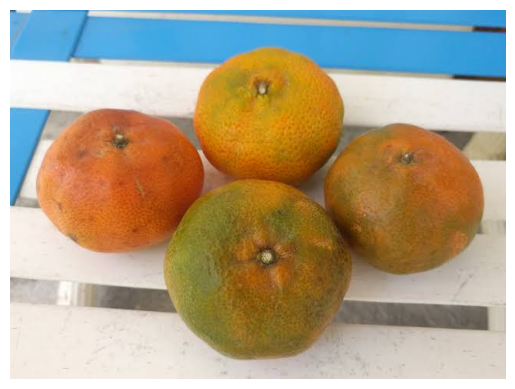

Predicted class: fresh
Confidence: 81.36%


In [27]:
from PIL import Image
import torch
from torchvision import transforms
import matplotlib.pyplot as plt

image = Image.open("orange.jpg").convert("RGB")

transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        [0.485, 0.456, 0.406],
        [0.229, 0.224, 0.225]
    )
])

image_tensor = transform(image).unsqueeze(0)
device = next(model.parameters()).device
image_tensor = image_tensor.to(device)

model.eval()

with torch.no_grad():
    outputs = model(image_tensor)
    probabilities = torch.softmax(outputs, dim=1)
    predicted_index = probabilities.argmax(dim=1).item()

class_names = train_dataset.classes

plt.imshow(image)
plt.axis("off")
plt.show()

print("Predicted class:", class_names[predicted_index])
print(f"Confidence: {probabilities[0][predicted_index].item() * 100:.2f}%")

In [28]:
from google.colab import files

uploaded = files.upload()

Saving orange_2.jpg to orange_2 (4).jpg


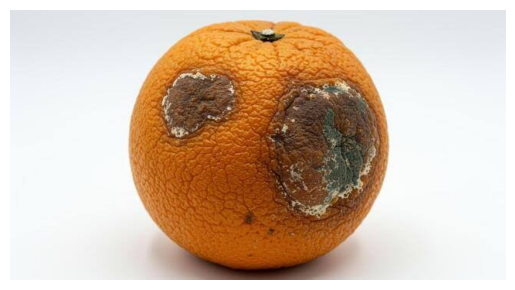

Predicted class: fresh
Confidence: 90.64%


In [29]:
from PIL import Image
import torch
from torchvision import transforms
import matplotlib.pyplot as plt

image = Image.open("orange_2 (4).jpg").convert("RGB")

transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        [0.485, 0.456, 0.406],
        [0.229, 0.224, 0.225]
    )
])

image_tensor = transform(image).unsqueeze(0)
device = next(model.parameters()).device
image_tensor = image_tensor.to(device)

model.eval()

with torch.no_grad():
    outputs = model(image_tensor)
    probabilities = torch.softmax(outputs, dim=1)
    predicted_index = probabilities.argmax(dim=1).item()

class_names = train_dataset.classes

plt.imshow(image)
plt.axis("off")
plt.show()

print("Predicted class:", class_names[predicted_index])
print(f"Confidence: {probabilities[0][predicted_index].item() * 100:.2f}%")

In [31]:
from google.colab import files

uploaded = files.upload()

Saving b (5).jpg to b (5).jpg


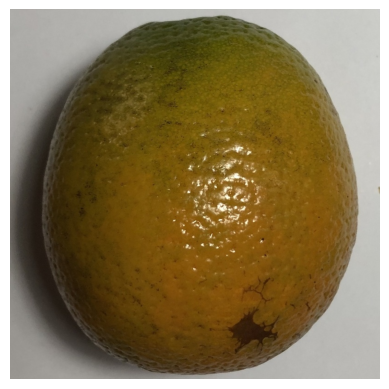

Predicted class: canker

Class-wise probabilities:
blackspot: 21.93%
canker: 74.21%
fresh: 1.57%
grenning: 2.30%


In [32]:
from PIL import Image
import torch
from torchvision import transforms
import matplotlib.pyplot as plt

image = Image.open("b (5).jpg").convert("RGB")

transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        [0.485, 0.456, 0.406],
        [0.229, 0.224, 0.225]
    )
])

image_tensor = transform(image).unsqueeze(0)
device = next(model.parameters()).device
image_tensor = image_tensor.to(device)

model.eval()

with torch.no_grad():
    outputs = model(image_tensor)
    probabilities = torch.softmax(outputs, dim=1)

class_names = train_dataset.classes
predicted_index = probabilities.argmax(dim=1).item()

plt.imshow(image)
plt.axis("off")
plt.show()

print("Predicted class:", class_names[predicted_index])
print("\nClass-wise probabilities:")

for i, name in enumerate(class_names):
    print(f"{name}: {probabilities[0][i].item() * 100:.2f}%")

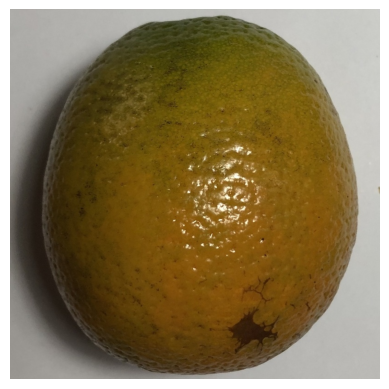

Image size: (800, 800)


In [33]:
from PIL import Image
import matplotlib.pyplot as plt

image = Image.open("b (5).jpg").convert("RGB")

plt.imshow(image)
plt.axis("off")
plt.show()

print("Image size:", image.size)

In [34]:
import torch
from torchvision import transforms

transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        [0.485, 0.456, 0.406],
        [0.229, 0.224, 0.225]
    )
])

image_tensor = transform(image).unsqueeze(0)

device = next(model.parameters()).device
image_tensor = image_tensor.to(device)

model.eval()

with torch.no_grad():
    outputs = model(image_tensor)
    probabilities = torch.softmax(outputs, dim=1)

predicted_index = probabilities.argmax(dim=1).item()
class_names = train_dataset.classes

print("Predicted class:", class_names[predicted_index])
print("\nClass probabilities:")

for i, name in enumerate(class_names):
    print(f"{name}: {probabilities[0][i].item() * 100:.2f}%")

Predicted class: canker

Class probabilities:
blackspot: 21.93%
canker: 74.21%
fresh: 1.57%
grenning: 2.30%


In [37]:
from google.colab import files
uploaded = files.upload()


KeyboardInterrupt



In [36]:
from PIL import Image
import torch
from torchvision import transforms

# Load the uploaded image
image = Image.open("orange_3.jpg").convert("RGB")

# Preprocess the image
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        [0.485, 0.456, 0.406],
        [0.229, 0.224, 0.225]
    )
])

image_tensor = transform(image).unsqueeze(0)
device = next(model.parameters()).device
image_tensor = image_tensor.to(device)

# Predict
model.eval()
with torch.no_grad():
    outputs = model(image_tensor)
    probabilities = torch.softmax(outputs, dim=1)

predicted_index = probabilities.argmax(dim=1).item()

print("Predicted class:", train_dataset.classes[predicted_index])

for i, name in enumerate(train_dataset.classes):
    print(f"{name}: {probabilities[0][i].item() * 100:.2f}%")

Predicted class: fresh
blackspot: 0.89%
canker: 8.88%
fresh: 87.37%
grenning: 2.86%


In [39]:
from google.colab import files
uploaded = files.upload()

Saving orange_4.webp to orange_4.webp


In [40]:
from PIL import Image
import torch
from torchvision import transforms

image = Image.open("orange_4.webp").convert("RGB")

transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        [0.485, 0.456, 0.406],
        [0.229, 0.224, 0.225]
    )
])

image_tensor = transform(image).unsqueeze(0)
image_tensor = image_tensor.to(next(model.parameters()).device)

model.eval()
with torch.no_grad():
    probabilities = torch.softmax(model(image_tensor), dim=1)

class_names = train_dataset.classes
predicted_index = probabilities.argmax(dim=1).item()

print("Predicted class:", class_names[predicted_index])

for i, name in enumerate(class_names):
    print(f"{name}: {probabilities[0][i].item() * 100:.2f}%")

Predicted class: grenning
blackspot: 15.41%
canker: 4.74%
fresh: 8.44%
grenning: 71.41%


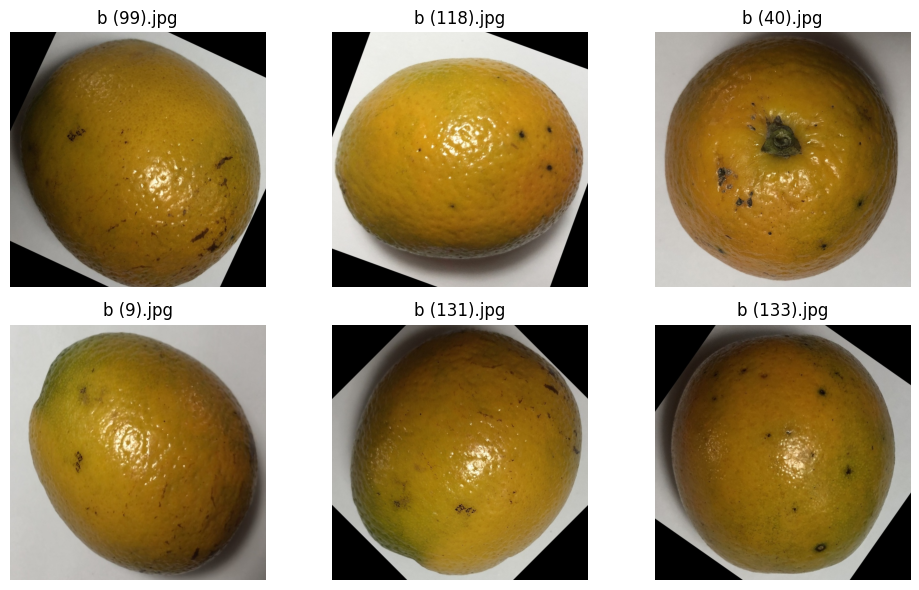

In [41]:
import os
import matplotlib.pyplot as plt
from PIL import Image

folder = "/content/avocado_dataset/train/blackspot"

files = os.listdir(folder)[:6]

fig, axes = plt.subplots(2, 3, figsize=(10, 6))

for ax, filename in zip(axes.flat, files):
    img = Image.open(os.path.join(folder, filename)).convert("RGB")
    ax.imshow(img)
    ax.set_title(filename)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [1]:
print("Checking MobileNetV2 and training variables...")

for name in list(globals()):
    if any(word in name.lower() for word in [
        "mobilenet", "model", "test_loader",
        "x_test", "y_test", "class_names", "history"
    ]):
        obj = globals()[name]
        print(f"{name}: {type(obj).__name__}")

Checking MobileNetV2 and training variables...


In [2]:
print("MobileNetV2 model available:", "mobilenet_model" in globals())
print("ResNet18 model available:", "resnet_model" in globals())

MobileNetV2 model available: False
ResNet18 model available: False


In [4]:

# Find model-related variables currently in memory

for name, obj in globals().copy().items():
    if any(word in name.lower() for word in ["model", "mobilenet", "resnet", "svm", "forest", "classifier"]):
        if not name.startswith("_"):
            print(name, ":", type(obj).__name__)


In [5]:

# Test 1: Check the current Python environment

print("Python environment is running!")

print("\nDataset and model-related variables:")

found = False

for name, obj in globals().copy().items():
    if not name.startswith("_") and any(
        word in name.lower()
        for word in ["image", "dataset", "train", "test",
                     "model", "loader", "class"]
    ):
        print(f"{name}: {type(obj).__name__}")
        found = True

if not found:
    print("No matching variables found.")


Python environment is running!

Dataset and model-related variables:
No matching variables found.


In [1]:

print("Checking Model 2 components...")

for name in [
    "model",
    "mobilenet_model",
    "resnet_model",
    "resnet18",
    "train_dataset",
    "test_dataset",
    "train_loader",
    "test_loader"
]:
    print(f"{name}: {'Available' if name in globals() else 'Not available'}")


Checking Model 2 components...
model: Not available
mobilenet_model: Not available
resnet_model: Not available
resnet18: Not available
train_dataset: Not available
test_dataset: Not available
train_loader: Not available
test_loader: Not available


In [2]:
import os
import torch

DATASET_PATH = "/content/avocado_dataset"
CLASSES = ["canker", "grenning", "blackspot", "fresh"]

print("GPU available:", torch.cuda.is_available())
print("Train folder exists:", os.path.exists(f"{DATASET_PATH}/train"))
print("Test folder exists:", os.path.exists(f"{DATASET_PATH}/test"))

for split in ["train", "test"]:
    print(f"\n{split.upper()} dataset:")
    for cls in CLASSES:
        folder = os.path.join(DATASET_PATH, split, cls)
        count = len(os.listdir(folder)) if os.path.exists(folder) else 0
        print(f"{cls}: {count} images")

GPU available: True
Train folder exists: False
Test folder exists: False

TRAIN dataset:
canker: 0 images
grenning: 0 images
blackspot: 0 images
fresh: 0 images

TEST dataset:
canker: 0 images
grenning: 0 images
blackspot: 0 images
fresh: 0 images


In [3]:
import torch

print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("GPU not enabled yet — check Runtime settings.")

GPU available: True
GPU: Tesla T4


In [4]:
import os
import torch
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

DATASET_PATH = "/content/avocado_dataset"
BATCH_SIZE = 32
IMAGE_SIZE = 224

# Image preprocessing
train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

test_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# Load datasets
train_dataset = datasets.ImageFolder(
    os.path.join(DATASET_PATH, "train"),
    transform=train_transform
)

test_dataset = datasets.ImageFolder(
    os.path.join(DATASET_PATH, "test"),
    transform=test_transform
)

# Create data loaders
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2
)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)
print("Classes:", train_dataset.classes)
print("Training images:", len(train_dataset))
print("Testing images:", len(test_dataset))
print("Training batches:", len(train_loader))
print("Testing batches:", len(test_loader))

FileNotFoundError: [Errno 2] No such file or directory: '/content/avocado_dataset/train'

In [5]:
import os

for root, dirs, files in os.walk("/content"):
    if "train" in dirs and "test" in dirs:
        print("Dataset location found:", root)
        print("Train path:", os.path.join(root, "train"))
        print("Test path:", os.path.join(root, "test"))

In [6]:
import os
import zipfile

ZIP_PATH = "/content/Orange Dataset.zip"
EXTRACT_PATH = "/content/avocado_dataset"

if os.path.exists(ZIP_PATH):
    with zipfile.ZipFile(ZIP_PATH, "r") as zip_ref:
        zip_ref.extractall(EXTRACT_PATH)
    print("Dataset extracted successfully!")
else:
    print("ZIP file not found. Please upload Orange Dataset.zip again.")

print("\nExtracted folders:")
print(os.listdir(EXTRACT_PATH) if os.path.exists(EXTRACT_PATH) else "No dataset folder")

ZIP file not found. Please upload Orange Dataset.zip again.

Extracted folders:
No dataset folder


In [2]:
from google.colab import files

uploaded = files.upload()

Saving Orange Dataset.zip to Orange Dataset.zip


In [3]:
import os

print("ZIP file exists:", os.path.exists("/content/Orange Dataset.zip"))

ZIP file exists: True


In [4]:
import os
import zipfile

zip_path = "/content/Orange Dataset.zip"
extract_path = "/content/avocado_dataset"

os.makedirs(extract_path, exist_ok=True)

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("Extraction completed!")
print("Folders:", os.listdir(extract_path))

Extraction completed!
Folders: ['test', 'train']


In [5]:
import os
import torch
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

DATASET_PATH = "/content/avocado_dataset"
BATCH_SIZE = 32
IMAGE_SIZE = 224

train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

test_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

train_dataset = datasets.ImageFolder(
    os.path.join(DATASET_PATH, "train"),
    transform=train_transform
)

test_dataset = datasets.ImageFolder(
    os.path.join(DATASET_PATH, "test"),
    transform=test_transform
)

train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE,
    shuffle=True, num_workers=2
)

test_loader = DataLoader(
    test_dataset, batch_size=BATCH_SIZE,
    shuffle=False, num_workers=2
)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)
print("Classes:", train_dataset.classes)
print("Training images:", len(train_dataset))
print("Testing images:", len(test_dataset))
print("Training batches:", len(train_loader))
print("Testing batches:", len(test_loader))

Device: cuda
Classes: ['blackspot', 'canker', 'fresh', 'grenning']
Training images: 991
Testing images: 99
Training batches: 31
Testing batches: 4
